# مشروع الأربعاء: رحلة تحليل بيانات السكري
## Task 1: فهم المشكلة (Problem Understanding)

الهدف من المشروع هو معرفة العوامل التي ترتبط بالإصابة بمرض السكري، حتى تساعد النتائج العيادة على التركيز على الفئات الأكثر عرضة وإجراء الفحص المبكر.

تحتوي البيانات على 768 امرأة و9 أعمدة.

العمود المستهدف هو `Outcome`:
- القيمة 1 تعني الإصابة بالسكري.
- القيمة 0 تعني عدم الإصابة بالسكري.

المستفيد من هذا التحليل هو الطبيب والعيادة، لمساعدتهم على فهم العوامل المرتبطة بالسكري.  

## Task 2: أول نظرة على البيانات (Initial Data Inspection)

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)
display(df.head())  

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [29]:
print("Data types:")
display(df.dtypes)

print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Statistical summary:")
display(df.describe())

Data types:


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0
Statistical summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [30]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zero values in medical columns:")
display(df[zero_columns].eq(0).sum())

Zero values in medical columns:


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [31]:
zero_rows = df[zero_columns].eq(0).any(axis=1).sum()

print("Total rows affected by zero values:", zero_rows)
print("Total rows in dataset:", len(df))

Total rows affected by zero values: 376
Total rows in dataset: 768


## Task 3: تنظيف البيانات (Data Cleaning & Decision Log)

### المشكلة المكتشفة

لاحظت أن البيانات لا تحتوي على قيم مفقودة ظاهرة باستخدام `isnull()`، لكن بعد فحص الأصفار اكتشفت وجود أصفار غير منطقية في بعض القياسات الطبية.

كانت النتائج كالتالي:
- Glucose: عدد الأصفار 5.
- BloodPressure: عدد الأصفار 35.
- SkinThickness: عدد الأصفار 227.
- Insulin: عدد الأصفار 374.
- BMI: عدد الأصفار 11.

إجمالي الصفوف المتأثرة بالأصفار هو 376 صفًا من أصل 768، أي حوالي 49%.

### قرار التنظيف

قررت عدم حذف الصفوف المتأثرة؛ لأن ذلك سيؤدي إلى فقدان كمية كبيرة من البيانات. سأتعامل مع الأصفار غير المنطقية باعتبارها قياسات مفقودة، ثم أدرس تعويضها بالوسيط (Median) للمحافظة على أكبر قدر ممكن من البيانات.

In [32]:
# Create a copy before cleaning
df_clean = df.copy()

# Replace invalid zeros with NaN
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in zero_columns:
    df_clean[col] = df_clean[col].replace(0, np.nan)

# Fill missing values with the median
for col in zero_columns:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("Dataset shape after cleaning:", df_clean.shape)

Missing values after cleaning:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dataset shape after cleaning: (768, 9)


In [33]:
for col in zero_columns:
    print(col, ":", df[col].eq(0).sum(), "values replaced")

Glucose : 5 values replaced
BloodPressure : 35 values replaced
SkinThickness : 227 values replaced
Insulin : 374 values replaced
BMI : 11 values replaced


### نتائج التنظيف (Cleaning Results)

بعد معالجة البيانات، استبدلت الأصفار غير المنطقية بالقيم المفقودة ثم عوضتها بالوسيط (Median).

عدد القيم التي تمت معالجتها:
- Glucose: تم تعويض 5 قيم.
- BloodPressure: تم تعويض 35 قيمة.
- SkinThickness: تم تعويض 227 قيمة.
- Insulin: تم تعويض 374 قيمة.
- BMI: تم تعويض 11 قيمة.

اخترت الوسيط لأنه أقل تأثرًا بالقيم المرتفعة والمنخفضة مقارنة بالمتوسط.

احتفظت بجميع الصفوف، وأصبح عدد القيم المفقودة بعد التنظيف صفرًا، وبقي حجم البيانات 768 صفًا و9 أعمدة.

## Task 4: التحليل الاستكشافي للبيانات (Exploratory Data Analysis - EDA)

في هذه المرحلة سأحلل البيانات باستخدام الرسوم البيانية لفهم توزيع حالات السكري، ومقارنة خصائص المصابات وغير المصابات، واكتشاف العوامل التي قد ترتبط بالإصابة بالسكري.  

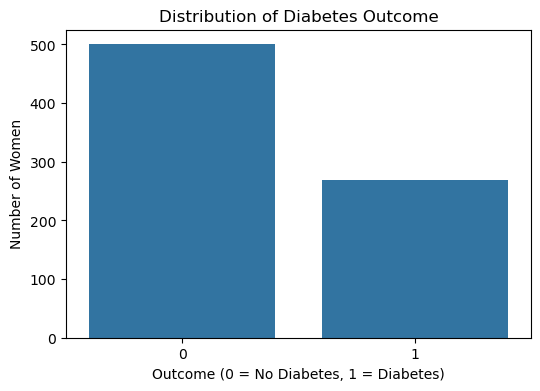

In [34]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="Outcome")

plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Women")

plt.show()

يوضح الرسم البياني أن عدد النساء غير المصابات بالسكري بلغ 500 امرأة بنسبة 65.10%، بينما بلغ عدد المصابات بالسكري 268 امرأة بنسبة 34.90%.

نلاحظ أن نسبة غير المصابات أكبر من نسبة المصابات، ومع ذلك تمثل المصابات حوالي 35% من العينة، وهي نسبة تستحق الاهتمام عند تحليل العوامل المرتبطة بالسكري.  

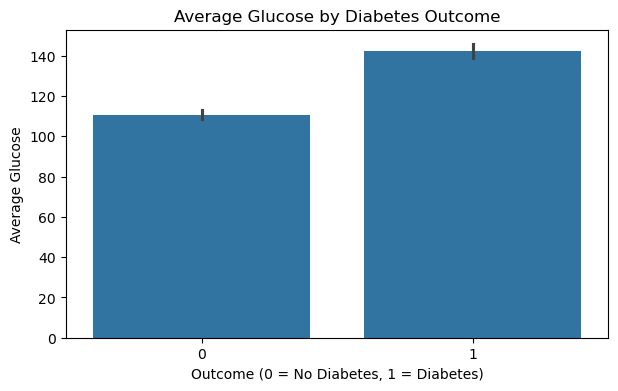

In [35]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x="Outcome", y="Glucose")

plt.title("Average Glucose by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average Glucose")

plt.show()

يوضح الرسم البياني أن متوسط مستوى الجلوكوز لدى النساء غير المصابات بالسكري بلغ 110.68، بينما بلغ لدى المصابات بالسكري 142.13.

نلاحظ أن متوسط الجلوكوز أعلى لدى المصابات بالسكري بحوالي 31.45، وهذا يشير إلى وجود ارتباط بين ارتفاع مستوى الجلوكوز والإصابة بالسكري في هذه البيانات.

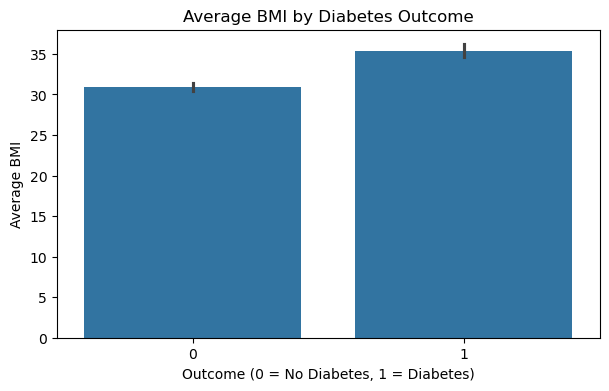

In [36]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x="Outcome", y="BMI")

plt.title("Average BMI by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average BMI")

plt.show()

يوضح الرسم البياني أن متوسط مؤشر كتلة الجسم (BMI) لدى النساء غير المصابات بالسكري بلغ 30.89، بينما بلغ لدى المصابات بالسكري 35.38.

نلاحظ أن متوسط مؤشر كتلة الجسم أعلى لدى المصابات بالسكري بحوالي 4.50، وهذا يشير إلى وجود ارتباط بين ارتفاع مؤشر كتلة الجسم والإصابة بالسكري في هذه البيانات.

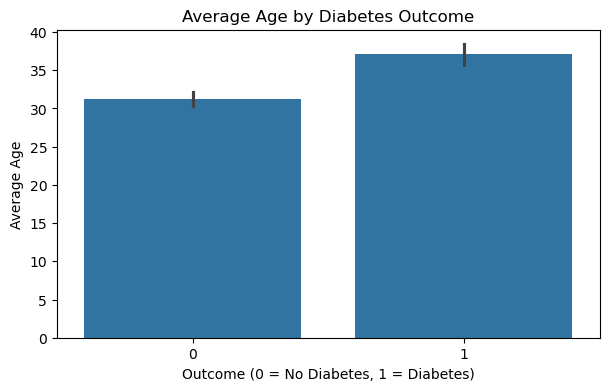

In [37]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x="Outcome", y="Age")

plt.title("Average Age by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average Age")

plt.show()

يوضح الرسم البياني أن متوسط العمر لدى النساء غير المصابات بالسكري بلغ 31.19 سنة، بينما بلغ لدى المصابات بالسكري 37.07 سنة.

نلاحظ أن متوسط العمر لدى المصابات بالسكري أكبر بحوالي 5.88 سنوات، وهذا يشير إلى وجود ارتباط بين العمر والإصابة بالسكري في هذه البيانات.  

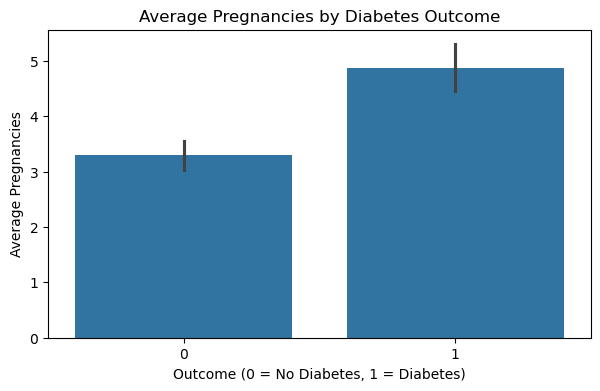

In [38]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x="Outcome", y="Pregnancies")

plt.title("Average Pregnancies by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average Pregnancies")

plt.show()

يوضح الرسم البياني أن متوسط عدد مرات الحمل لدى النساء غير المصابات بالسكري بلغ 3.30، بينما بلغ لدى المصابات بالسكري 4.87.

نلاحظ أن متوسط عدد مرات الحمل أعلى لدى المصابات بالسكري بحوالي 1.57، وهذا يشير إلى وجود ارتباط بين عدد مرات الحمل والإصابة بالسكري في هذه البيانات.

In [39]:
correlation = df_clean.corr(numeric_only=True)["Outcome"].drop("Outcome")
display(correlation.sort_values(ascending=False))

Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64

### أهم العوامل المرتبطة بالإصابة بالسكري

من خلال تحليل معاملات الارتباط، وجدت أن مستوى الجلوكوز هو أكثر الأعمدة ارتباطًا بنتيجة السكري بمعامل 0.493، يليه مؤشر كتلة الجسم (BMI) بمعامل 0.312، ثم العمر بمعامل 0.238، وعدد مرات الحمل بمعامل 0.222.

تشير هذه النتائج إلى أن الجلوكوز ومؤشر كتلة الجسم والعمر وعدد مرات الحمل من أبرز العوامل المرتبطة بالسكري في هذه البيانات.

يجب الانتباه إلى أن الارتباط لا يعني بالضرورة وجود علاقة سببية.  

## Task 5: هندسة الخصائص (Feature Engineering)

في هذه المرحلة سأضيف خصائص جديدة مشتقة من الأعمدة الموجودة، بهدف استخراج معلومات إضافية قد تساعد في فهم العلاقة بين البيانات والإصابة بالسكري.  

In [40]:
df_clean["Glucose_BMI"] = df_clean["Glucose"] * df_clean["BMI"]

display(df_clean[["Glucose", "BMI", "Glucose_BMI"]].head())

,Glucose,BMI,Glucose_BMI
0,148.0,33.6,4972.8
1,85.0,26.6,2261.0
2,183.0,23.3,4263.9
3,89.0,28.1,2500.9
4,137.0,43.1,5904.7


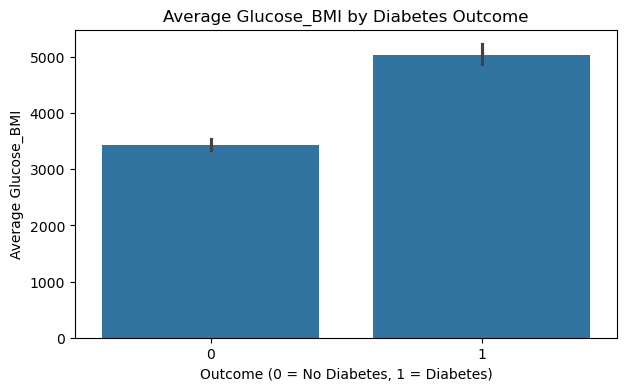

In [41]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x="Outcome", y="Glucose_BMI")

plt.title("Average Glucose_BMI by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Average Glucose_BMI")

plt.show()

يوضح الرسم البياني أن متوسط الخاصية الجديدة (Glucose_BMI) لدى النساء غير المصابات بالسكري بلغ 3437.63، بينما بلغ لدى المصابات بالسكري 5039.65.

نلاحظ أن المتوسط أعلى لدى المصابات بالسكري بحوالي 1602.02، وهذا يشير إلى وجود ارتباط بين الخاصية الجديدة ونتيجة السكري في هذه البيانات.  

In [42]:
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=["20-30", "31-40", "41-50", "51+"]
)

display(df_clean[["Age", "Age_Group"]].head(10))

,Age,Age_Group
0,50,41-50
1,31,31-40
2,32,31-40
3,21,20-30
4,33,31-40
5,30,20-30
6,26,20-30
7,29,20-30
8,53,51+
9,54,51+


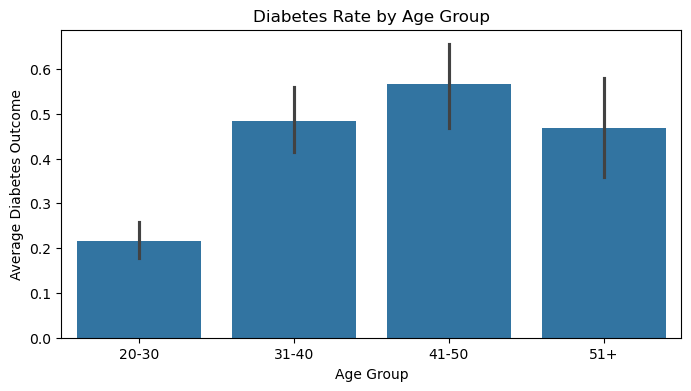

In [43]:
plt.figure(figsize=(8, 4))

sns.barplot(data=df_clean, x="Age_Group", y="Outcome")

plt.title("Diabetes Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Diabetes Outcome")

plt.show()

يوضح الرسم البياني اختلاف نسبة الإصابة بالسكري بين الفئات العمرية. بلغت النسبة 21.58% للفئة 20-30 سنة، و48.41% للفئة 31-40 سنة، و56.64% للفئة 41-50 سنة، و46.91% للفئة 51 سنة فأكثر.

نلاحظ أن أعلى نسبة إصابة كانت في الفئة العمرية 41-50 سنة بنسبة 56.64%، بينما كانت أقل نسبة في الفئة 20-30 سنة بنسبة 21.58%.   

### خلاصة هندسة الخصائص

أنشأت خاصيتين جديدتين من البيانات الأصلية. الأولى Glucose_BMI، وهي حاصل ضرب مستوى الجلوكوز في مؤشر كتلة الجسم، وظهر أن متوسطها لدى المصابات بالسكري بلغ 5039.65 مقارنة بـ3437.63 لدى غير المصابات.

والخاصية الثانية Age_Group، قسمت فيها الأعمار إلى أربع فئات. وكانت أعلى نسبة إصابة بالسكري في الفئة العمرية 41-50 سنة بنسبة 56.64%.

ساعدتني هذه الخصائص على فهم البيانات من زوايا إضافية.  

## Task 6: اختيار الخصائص (Feature Selection)

في هذه المرحلة سأختار الخصائص الأكثر ارتباطًا بنتيجة السكري، بالاعتماد على نتائج التحليل ومعاملات الارتباط، حتى أجهز البيانات للمرحلة التالية.  

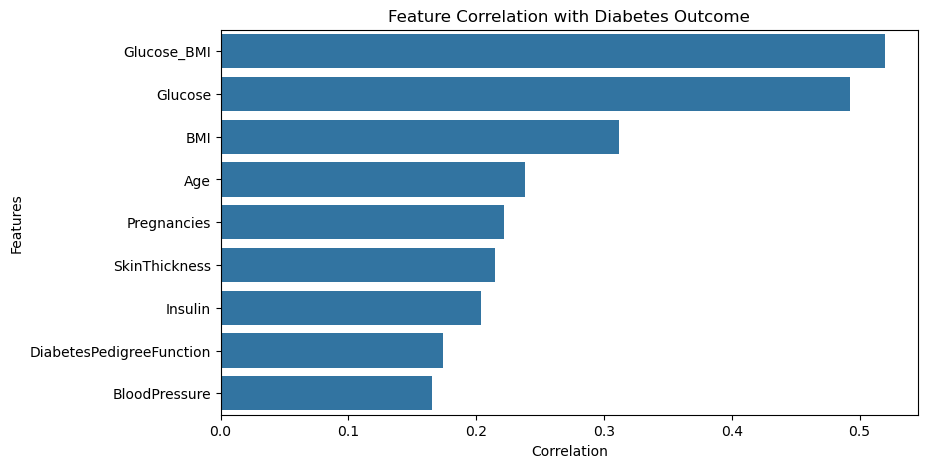

Glucose_BMI                 0.519906
Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64

In [44]:
feature_corr = df_clean.corr(numeric_only=True)["Outcome"].drop("Outcome")

feature_corr = feature_corr.sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(x=feature_corr.values, y=feature_corr.index)

plt.title("Feature Correlation with Diabetes Outcome")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

display(feature_corr)

### تحليل ارتباط الخصائص بنتيجة السكري

يوضح الرسم أن أعلى ارتباط كان للخاصية Glucose_BMI بمعامل 0.520، يليها Glucose بمعامل 0.493، ثم BMI بمعامل 0.312.

كما ظهر ارتباط للعمر بمعامل 0.238، وعدد مرات الحمل بمعامل 0.222.

بناءً على هذه النتائج، سأعطي الأولوية للخصائص ذات الارتباط الأعلى عند تجهيز البيانات، مع مراعاة أن الارتباط لا يعني السببية. 

### جدول قرار اختيار الخصائص

| الخاصية | معامل الارتباط | القرار | السبب |
|---|---:|---|---|
| Glucose_BMI | 0.520 | الاحتفاظ | أعلى ارتباط بنتيجة السكري |
| Glucose | 0.493 | الاحتفاظ | ارتباط قوي نسبيًا مع السكري |
| BMI | 0.312 | الاحتفاظ | من الخصائص المهمة في التحليل |
| Age | 0.238 | الاحتفاظ | يرتبط بنتيجة السكري |
| Pregnancies | 0.222 | الاحتفاظ | ظهر له ارتباط مع السكري |
| SkinThickness | 0.215 | الاستبعاد | ارتباطه أقل من الخصائص المختارة |
| Insulin | 0.204 | الاستبعاد | ارتباطه أقل من الخصائص المختارة |
| DiabetesPedigreeFunction | 0.174 | الاستبعاد | ارتباطه منخفض نسبيًا |
| BloodPressure | 0.166 | الاستبعاد | أقل معامل ارتباط بين الخصائص |

قررت الاحتفاظ بأعلى خمس خصائص حسب معاملات الارتباط، واستبعاد الخصائص الأربع الأقل ارتباطًا في هذا الاختيار.

هذا القرار مبني على نتائج هذه البيانات فقط، ولا يعني أن الخصائص المستبعدة غير مهمة طبيًا.  

In [45]:
selected_features = [
    "Glucose_BMI",
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies"
]

df_model = df_clean[selected_features + ["Outcome"]].copy()

print("Model-ready dataset shape:", df_model.shape)
display(df_model.head())

Model-ready dataset shape: (768, 6)


,Glucose_BMI,Glucose,BMI,Age,Pregnancies,Outcome
0,4972.8,148.0,33.6,50,6,1
1,2261.0,85.0,26.6,31,1,0
2,4263.9,183.0,23.3,32,8,1
3,2500.9,89.0,28.1,21,1,0
4,5904.7,137.0,43.1,33,0,1


In [46]:
df_model.to_csv("diabetes_model_ready.csv", index=False)

print("تم حفظ ملف diabetes_model_ready.csv بنجاح")

تم حفظ ملف diabetes_model_ready.csv بنجاح


## Task 7: النتائج والتوصيات (Results & Recommendations)

من خلال تحليل بيانات السكري، توصلت إلى أن مستوى الجلوكوز هو أكثر الخصائص ارتباطًا بالإصابة بالسكري، يليه مؤشر كتلة الجسم (BMI)، ثم العمر وعدد مرات الحمل.

كما ساعدتني هندسة الخصائص على إنشاء خاصية جديدة تجمع بين الجلوكوز ومؤشر كتلة الجسم، وظهر أن لها أعلى معامل ارتباط بنتيجة السكري بقيمة 0.520.

أوصي العيادة بالاهتمام بقياس مستوى الجلوكوز ومؤشر كتلة الجسم، ومتابعة الفئات العمرية التي ظهرت لديها نسب إصابة أعلى، مع إجراء الفحوصات المناسبة.

يجب الانتباه إلى أن النتائج توضح ارتباطات في البيانات، ولا تثبت أن هذه الخصائص تسبب مرض السكري.

## ملخص للطبيب (Doctor Summary)

1. يهدف هذا التحليل إلى دراسة العوامل المرتبطة بالإصابة بمرض السكري.
2. تحتوي البيانات على 768 امرأة و9 أعمدة.
3. بلغ عدد النساء المصابات بالسكري 268 امرأة بنسبة 34.90%.
4. بلغ عدد النساء غير المصابات بالسكري 500 امرأة بنسبة 65.10%.
5. كان مستوى الجلوكوز أكثر الخصائص الأصلية ارتباطًا بالسكري بمعامل 0.493.
6. جاء مؤشر كتلة الجسم (BMI) في المرتبة الثانية بمعامل ارتباط 0.312.
7. جاء العمر في المرتبة الثالثة بمعامل ارتباط 0.238.
8. كانت أعلى نسبة إصابة بين الفئات العمرية في فئة 41-50 سنة، وبلغت 56.64%.
9. كانت أكبر مشكلة في البيانات وجود أصفار غير منطقية في بعض القياسات، وتم التعامل معها كقيم مفقودة وتعويضها بالوسيط بدلًا من حذف الصفوف.
10. أوصي بالاهتمام بقياس الجلوكوز ومؤشر كتلة الجسم، ومتابعة الأشخاص الذين تظهر لديهم مؤشرات تستدعي الفحص.
11. من حدود هذا التحليل أن البيانات تخص نساء فقط، لذلك لا يمكن تعميم النتائج على جميع الفئات.
12. الارتباط بين الخصائص والسكري لا يعني بالضرورة أن هذه الخصائص تسبب المرض.   
